In [21]:
import sys
import os
sys.path.append('../')


import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
import pickle
import pprint

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.geometry import box
from shapely.ops import nearest_points

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier
from utils import get_tiles_as_gdf, get_window

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

np.set_printoptions(suppress=True)

In [3]:
device = 'cuda'

model_dir = os.path.join('../models_trained', wandb_id)
config_path = os.path.join(model_dir, 'config.json')
with open(config_path) as source:
    config = json.loads(source.read())


#Load trained model
model = MultiModalDriverClassifier(11,  **config)
model = model.to(device)

trained_weights = f'../models_trained/{wandb_id}/last.pt'
_ = model.load_state_dict(torch.load(trained_weights)['state_dict'])
_ = model.eval()

# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['val'], config)
val_dl = dataloaders['val']

In [166]:
forestloss_dir = '../../Vancutsem_yearloss'
tmf_extent = get_tiles_as_gdf(forestloss_dir)
tmf_extent.crs = 4326


# Load a land mask (for simplicity, this can be a GeoDataFrame of the world land mask)
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
# Filter world data to only include land areas
land_areas = gpd.overlay(world, tmf_extent, how='intersection')

/tmp/ipykernel_106135/1446822280.py:7: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
/tmp/ipykernel_106135/1446822280.py:9: UserWarning: `keep_geom_type=True` in overlay resulted in 1 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  land_areas = gpd.overlay(world, tmf_extent, how='intersection')


In [209]:
def plot_images(data, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images, figsize=(16, 10))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])



    fig.tight_layout()
    plt.show()
    
def plot_images_with_tmf(data, tmf, label, figsize=(16,16)):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(figsize[0], figsize[1]))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    ax[n_images].imshow(tmf.permute(1, 2, 0).numpy())
    ax[n_images].set_xticks([])
    ax[n_images].set_yticks([])
    
    fig.tight_layout()
    plt.show()
    



3404

driver                               shifting agriculture
sampleid                                        130004771
dataset                    tyukavina_congo_basin_agri.csv
country                                   Dem. Rep. Congo
geometry    POINT (23.392802080826815 -5.036872730749599)
block_id                                            134.0
split                                                 val
dst_size                                              NaN
Name: 1613, dtype: object
shifting agriculture


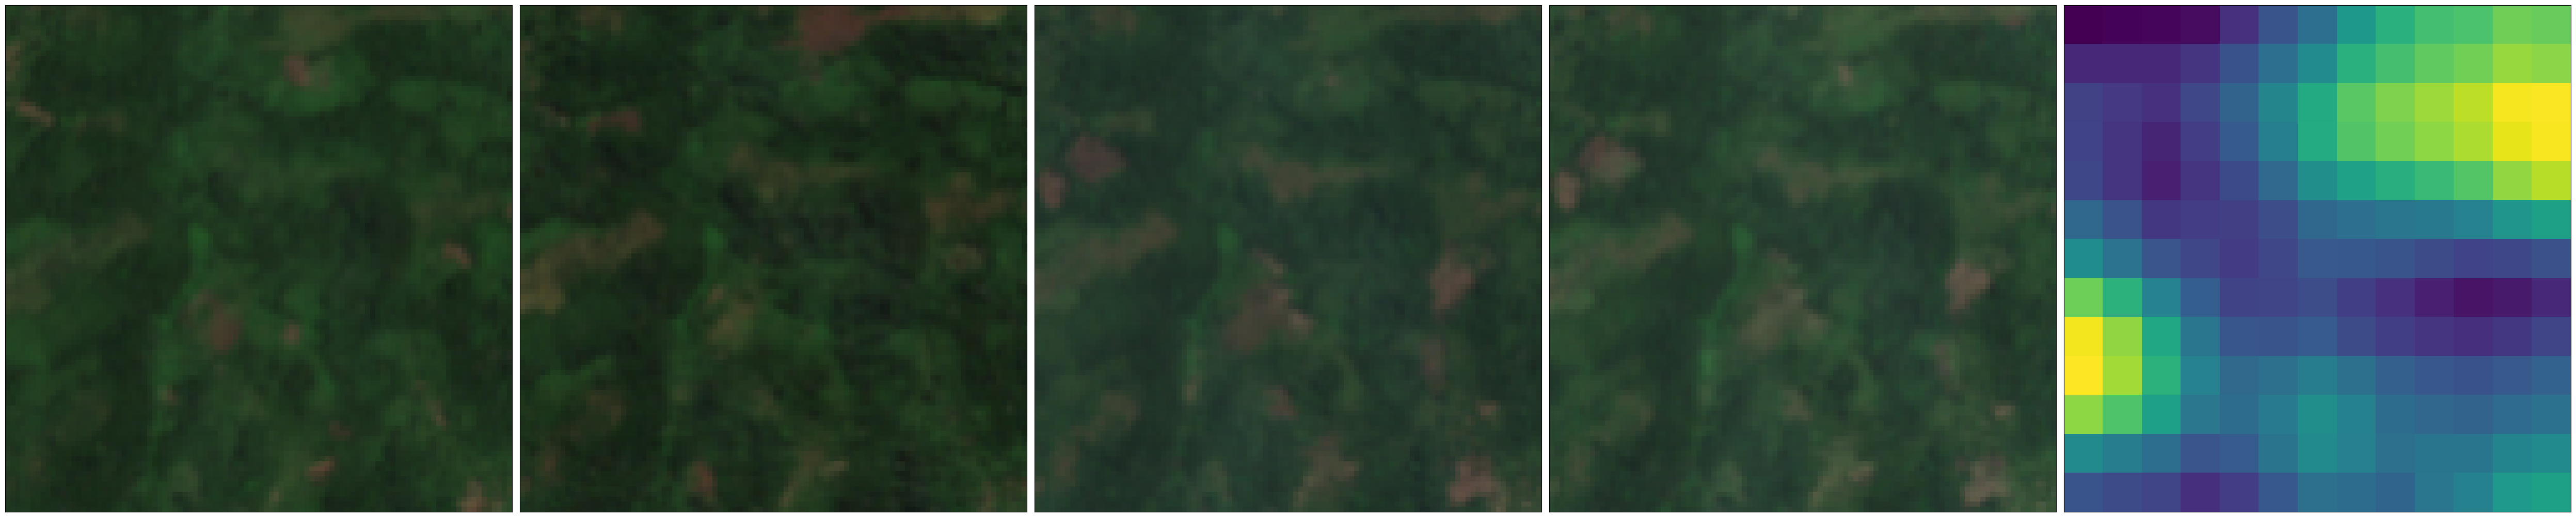

KeyboardInterrupt: Interrupted by user

In [230]:
while True:
    row = val_dl.dataset.img_labels.sample(1).iloc[0]
    if row.driver in ['coffee', 'soy', 'rubber', 'pasture', 'mining', 'palm oil','cocoa' ]:
        continue
        
    idx = row.name

    print(row)
    x, label = val_dl.dataset.__getitem__(idx)
    ts, loc, expansion_rates, forestloss = x 
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    ratessss = np.around(expansion_rates.numpy(),decimals=2)
    predssss = np.around(y_hat,decimals=3)
    rates = {}
    preds = {}
    for i, key in enumerate(LABEL_MAPPING.keys()):
        rates[key] = ratessss[i]
        preds[key] = predssss[i]
    
    

    #pprint.pprint(rates)
    #print()
    #pprint.pprint(preds)
    
        
    plot_images_with_tmf(ts, forestloss, label= inverse_label_mapping[label], figsize=(50,15))

    _waitforinput = input()

    clear_output(wait=True)

In [8]:
def _get_image_bbox(image_path):


    with rasterio.open(image_path) as src:
        lower_left = src.xy(105, 5, offset='ll')
        upper_left = src.xy(5, 5, offset='ul')

        lower_right = src.xy(105, 105, offset='lr')
        upper_right = src.xy(5, 105, offset='ur')

        #lower_left = src.xy(109, 10, offset='ll')
        #upper_left = src.xy(10, 10, offset='ul')
        #lower_right = src.xy(109, 109, offset='lr')
        #upper_right = src.xy(10, 109, offset='ur')    
        
    poly = Polygon([lower_left, upper_left, upper_right, lower_right])
    
    
    return poly

In [ ]:
'''
steps given a sampleid
1. , get a bounding box

'''

In [ ]:
#df = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv')

In [11]:
sampleid = 150103777

In [12]:
image_folder = f'../data/images/dataset_v5/four_images/{sampleid}/'

'20230630T135709_20230630T140406_T21MXM_cloud_prob_sum_0.tif'

In [ ]:
with rasterio.open() as source:
    

In [15]:
raster_path = os.path.join(image_folder, os.listdir(image_folder)[1])

In [17]:
bbox = _get_image_bbox(raster_path)

In [19]:
print(bbox)

POLYGON ((-55.206600337999035 -7.683925938637033, -55.206600337999035 -7.674838830434022, -55.19748944166075 -7.674838830434022, -55.19748944166075 -7.683925938637033, -55.206600337999035 -7.683925938637033))


In [20]:
forestloss_dir = '../../Vancutsem_yearloss'
tmf_extent = get_tiles_as_gdf(forestloss_dir)
tmf_extent.crs = 4326


In [22]:
with rasterio.open(raster_path) as src:
    raster_data = src.read()
    
    

In [51]:
raster_data[:, 5:105, 5:105].shape

(12, 100, 100)

In [41]:
raster_data.max()

5587

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


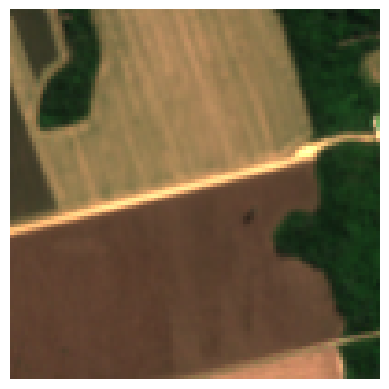

In [52]:
rgb_indices = [1,2,3]

img = raster_data[rgb_indices, 5:105, 5:105]
img = img/img.max()
img = img*1.7
plt.axis('off')

plt.imshow(img.transpose(1, 2, 0)[:,:,[2,1,0]])

In [55]:
forestloss_patch = f'../data/forestloss_tiles/dataset_v5/{sampleid}.tif'

In [56]:
with rasterio.open(forestloss_patch) as src:
    label_data = src.read(1,           
        out_shape=(
            100,
            100  
        ))

array([[ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       ...,
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False],
       [ True,  True,  True, ..., False, False, False]])

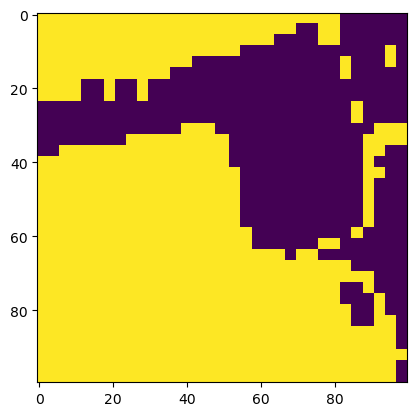

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


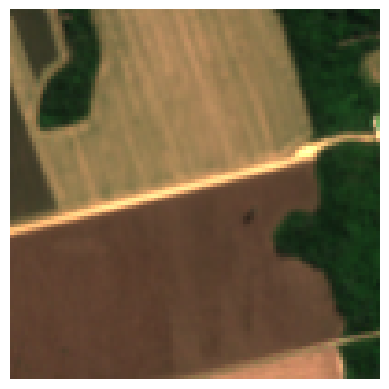

In [70]:
rgb_indices = [1,2,3]

img = raster_data[rgb_indices, 5:105, 5:105]
img = img/img.max()
img = img*1.7
plt.axis('off')

plt.imshow(img.transpose(1, 2, 0)[:,:,[2,1,0]])
#plt.imshow(np.logical_and(label_data>=2000, label_data<=2020), alpha=0.1,)

plt.show()

## Cleaned code for all classes

In [168]:
sampleids = [
    150103777, #soy
    190000122, # coffee
    20012478, # rubber
    20011327,  # rubber
    10233612, # pasture, would need tmf #10082490 same
    10487199, #pasture
    140022376, #mining
    #80076083, # forest plantation, not 100% 80075269
    80074833, #forest plantation, nice
    100006157, #urban
    80103063, #palm oil indo, ok
    90032710, #palm oil malaysia, better
    #30000593, #cocoa, ok
    #30009296, #cocoa ok #30009243 30001690 30001943
    30006564, # cocoa maybe this one better
    
    
    #130003877, #shifting, could be better #130017084 #130004771
    130004734, #shifting, is ok
    
    80265603, # other, indonesia agriculture
    180000794, # other, bolivia river, may need tmf
    10041328, #other, brazil river, maybe better
    10643721, #other brazil water


]

sampleid = 80265603
image_folder = f'../data/images/dataset_v5/four_images/{sampleid}/'

In [177]:
raster_path = os.path.join(image_folder, os.listdir(image_folder)[1])

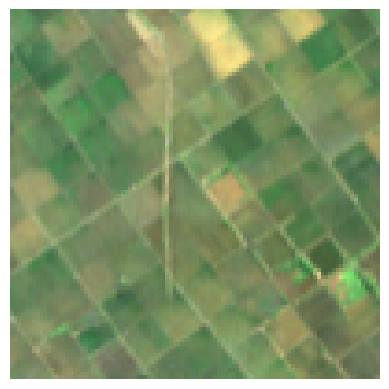

In [178]:
with rasterio.open(raster_path) as src:
    raster_data = src.read()
    
rgb_indices = [1,2,3]

img = raster_data[rgb_indices, 5:105, 5:105]
img = img/img.max()
img = img*1
plt.axis('off')

plt.imshow(img.transpose(1, 2, 0)[:,:,[2,1,0]])
plt.savefig('../data/tmp/other_rice.png',bbox_inches='tight', pad_inches=0)

In [ ]:
preds = []
for _i, row in tqdm.tqdm(df_soy.iterrows()):
    i = row.name
    x, label = val_dl.dataset.__getitem__(_soy_idx) #Get always the same input data 
    ts, loc, expansion_rates, forestloss = x 
    loc = torch.Tensor([row.geometry.y, row.geometry.x]) #Replace loc with a random location
    
    _ts, _loc, _expansion_rates, _forestloss = ts.unsqueeze(0).to(device), loc.unsqueeze(0).to(device), expansion_rates.unsqueeze(0).to(device), forestloss.unsqueeze(0).to(device) 
    y_hat = model(_ts, _loc, _expansion_rates, _forestloss)  #Location+img only model
    y_hat = F.softmax(y_hat, dim=1).detach().cpu().numpy().squeeze()
    
    #predssss = np.around(y_hat,decimals=3)
    preds.append(y_hat)
    

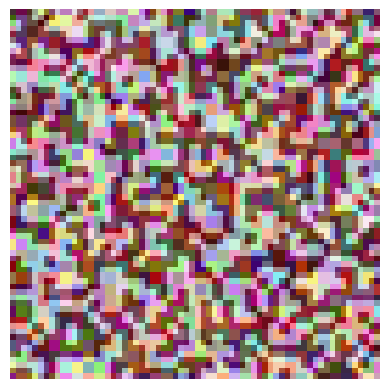

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a sample image and mask
image = np.random.rand(100, 100, 3)  # 100x100 RGB image with random colors
mask = np.random.randint(0, 2, (33, 33))  # 33x33 binary mask

# Plot the image
plt.imshow(image, interpolation='nearest')
plt.axis('off')

# Overlay the mask on the image
# Position the mask at the center of the image
top_left_x = (image.shape[1] - mask.shape[1]) // 2
top_left_y = (image.shape[0] - mask.shape[0]) // 2
plt.imshow(mask, cmap='Reds', alpha=0.5, extent=[top_left_x, top_left_x + mask.shape[1], 
                                                 top_left_y + mask.shape[0], top_left_y])

plt.show()

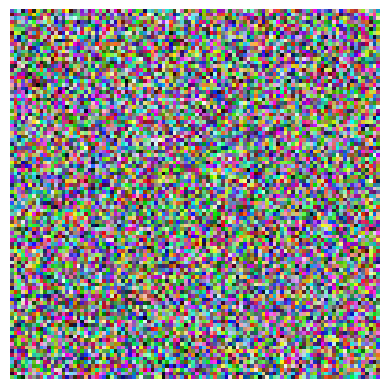

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a sample image and mask
image = np.random.rand(100, 100, 3)  # 100x100 RGB image with random colors
mask = np.random.randint(0, 2, (33, 33))  # 33x33 binary mask

# Plot the image
plt.imshow(image, interpolation='nearest')
plt.axis('off')

# Overlay the mask on the image
# Position the mask at the center of the image
top_left_x = (image.shape[1] - mask.shape[1]) // 2
top_left_y = (image.shape[0] - mask.shape[0]) // 2
#plt.imshow(mask, cmap='Reds', alpha=0.5, extent=[top_left_x, top_left_x + mask.shape[1], 
#                                                 top_left_y + mask.shape[0], top_left_y])

plt.show()

0